In [9]:
import osmnx as ox

import pandas as pd
import geopandas as gpd
import shapely
import pyrosm

pd.set_option("display.max_columns", None)

In [10]:
fp = "chile-latest.osm.pbf"
place_name = "Concepción, Chile"

place_string = "_".join(place_name.lower().split(",")[0].split(" "))

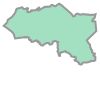

In [11]:
area_gdf = ox.geocode_to_gdf(place_name)
area = area_gdf.geometry.iloc[0]
area

In [12]:
# define the keys you want to query through a <key>: <value> dict

# the <value> for each <key> can be a list (i.e. ["hospital", "pharmacy"])
# also it can be True if you want to download all features with <key>

tags = {
    "amenity": True,
    # "shop": 
    # add other keys like "shop": True if you want
}

In [13]:
# load the file with all osm data and clip with boundary
osm = pyrosm.OSM(fp, bounding_box=area)

# download the features
pois = osm.get_pois(custom_filter=tags)

pois = pois.to_crs(32718)
pois.geometry = pois.geometry.centroid
pois = pois.to_crs(4326)

pois = pois[~pois["amenity"].isna()]
pois = pois[pois['amenity'] != 'bench']

pois.lon = pois.geometry.x
pois.lat = pois.geometry.y
pois = pois.rename(columns={"lon": "x", "lat": "y"})

pois = pois[["id", "x", "y", "amenity", "geometry"]]

In [14]:
# edges_gdf = gpd.read_file("./network/provincia_de_concepción.gpkg", layer="edges", encoding="latin-1")

In [15]:
pois.amenity.value_counts().to_dict()

{'parking': 309,
 'restaurant': 141,
 'school': 126,
 'fast_food': 105,
 'pharmacy': 92,
 'place_of_worship': 79,
 'waste_basket': 66,
 'cafe': 61,
 'parking_entrance': 44,
 'kindergarten': 44,
 'clinic': 39,
 'pub': 36,
 'bank': 34,
 'bar': 32,
 'toilets': 30,
 'fuel': 29,
 'university': 21,
 'bicycle_parking': 20,
 'nightclub': 18,
 'dentist': 18,
 'doctors': 16,
 'courthouse': 15,
 'fountain': 14,
 'atm': 13,
 'car_wash': 12,
 'college': 12,
 'community_centre': 11,
 'veterinary': 10,
 'fire_station': 10,
 'post_office': 9,
 'police': 9,
 'recycling': 9,
 'social_facility': 9,
 'bus_station': 9,
 'taxi': 8,
 'library': 7,
 'theatre': 7,
 'arts_centre': 7,
 'ice_cream': 6,
 'waste_disposal': 6,
 'prison': 5,
 'vending_machine': 4,
 'hospital': 4,
 'charging_station': 4,
 'telephone': 4,
 'shelter': 4,
 'marketplace': 3,
 'compressed_air': 3,
 'car_rental': 3,
 'studio': 2,
 'food_court': 2,
 'parking_space': 2,
 'internet_cafe': 2,
 'motorcycle_parking': 2,
 'clock': 2,
 'vehicle_ins

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

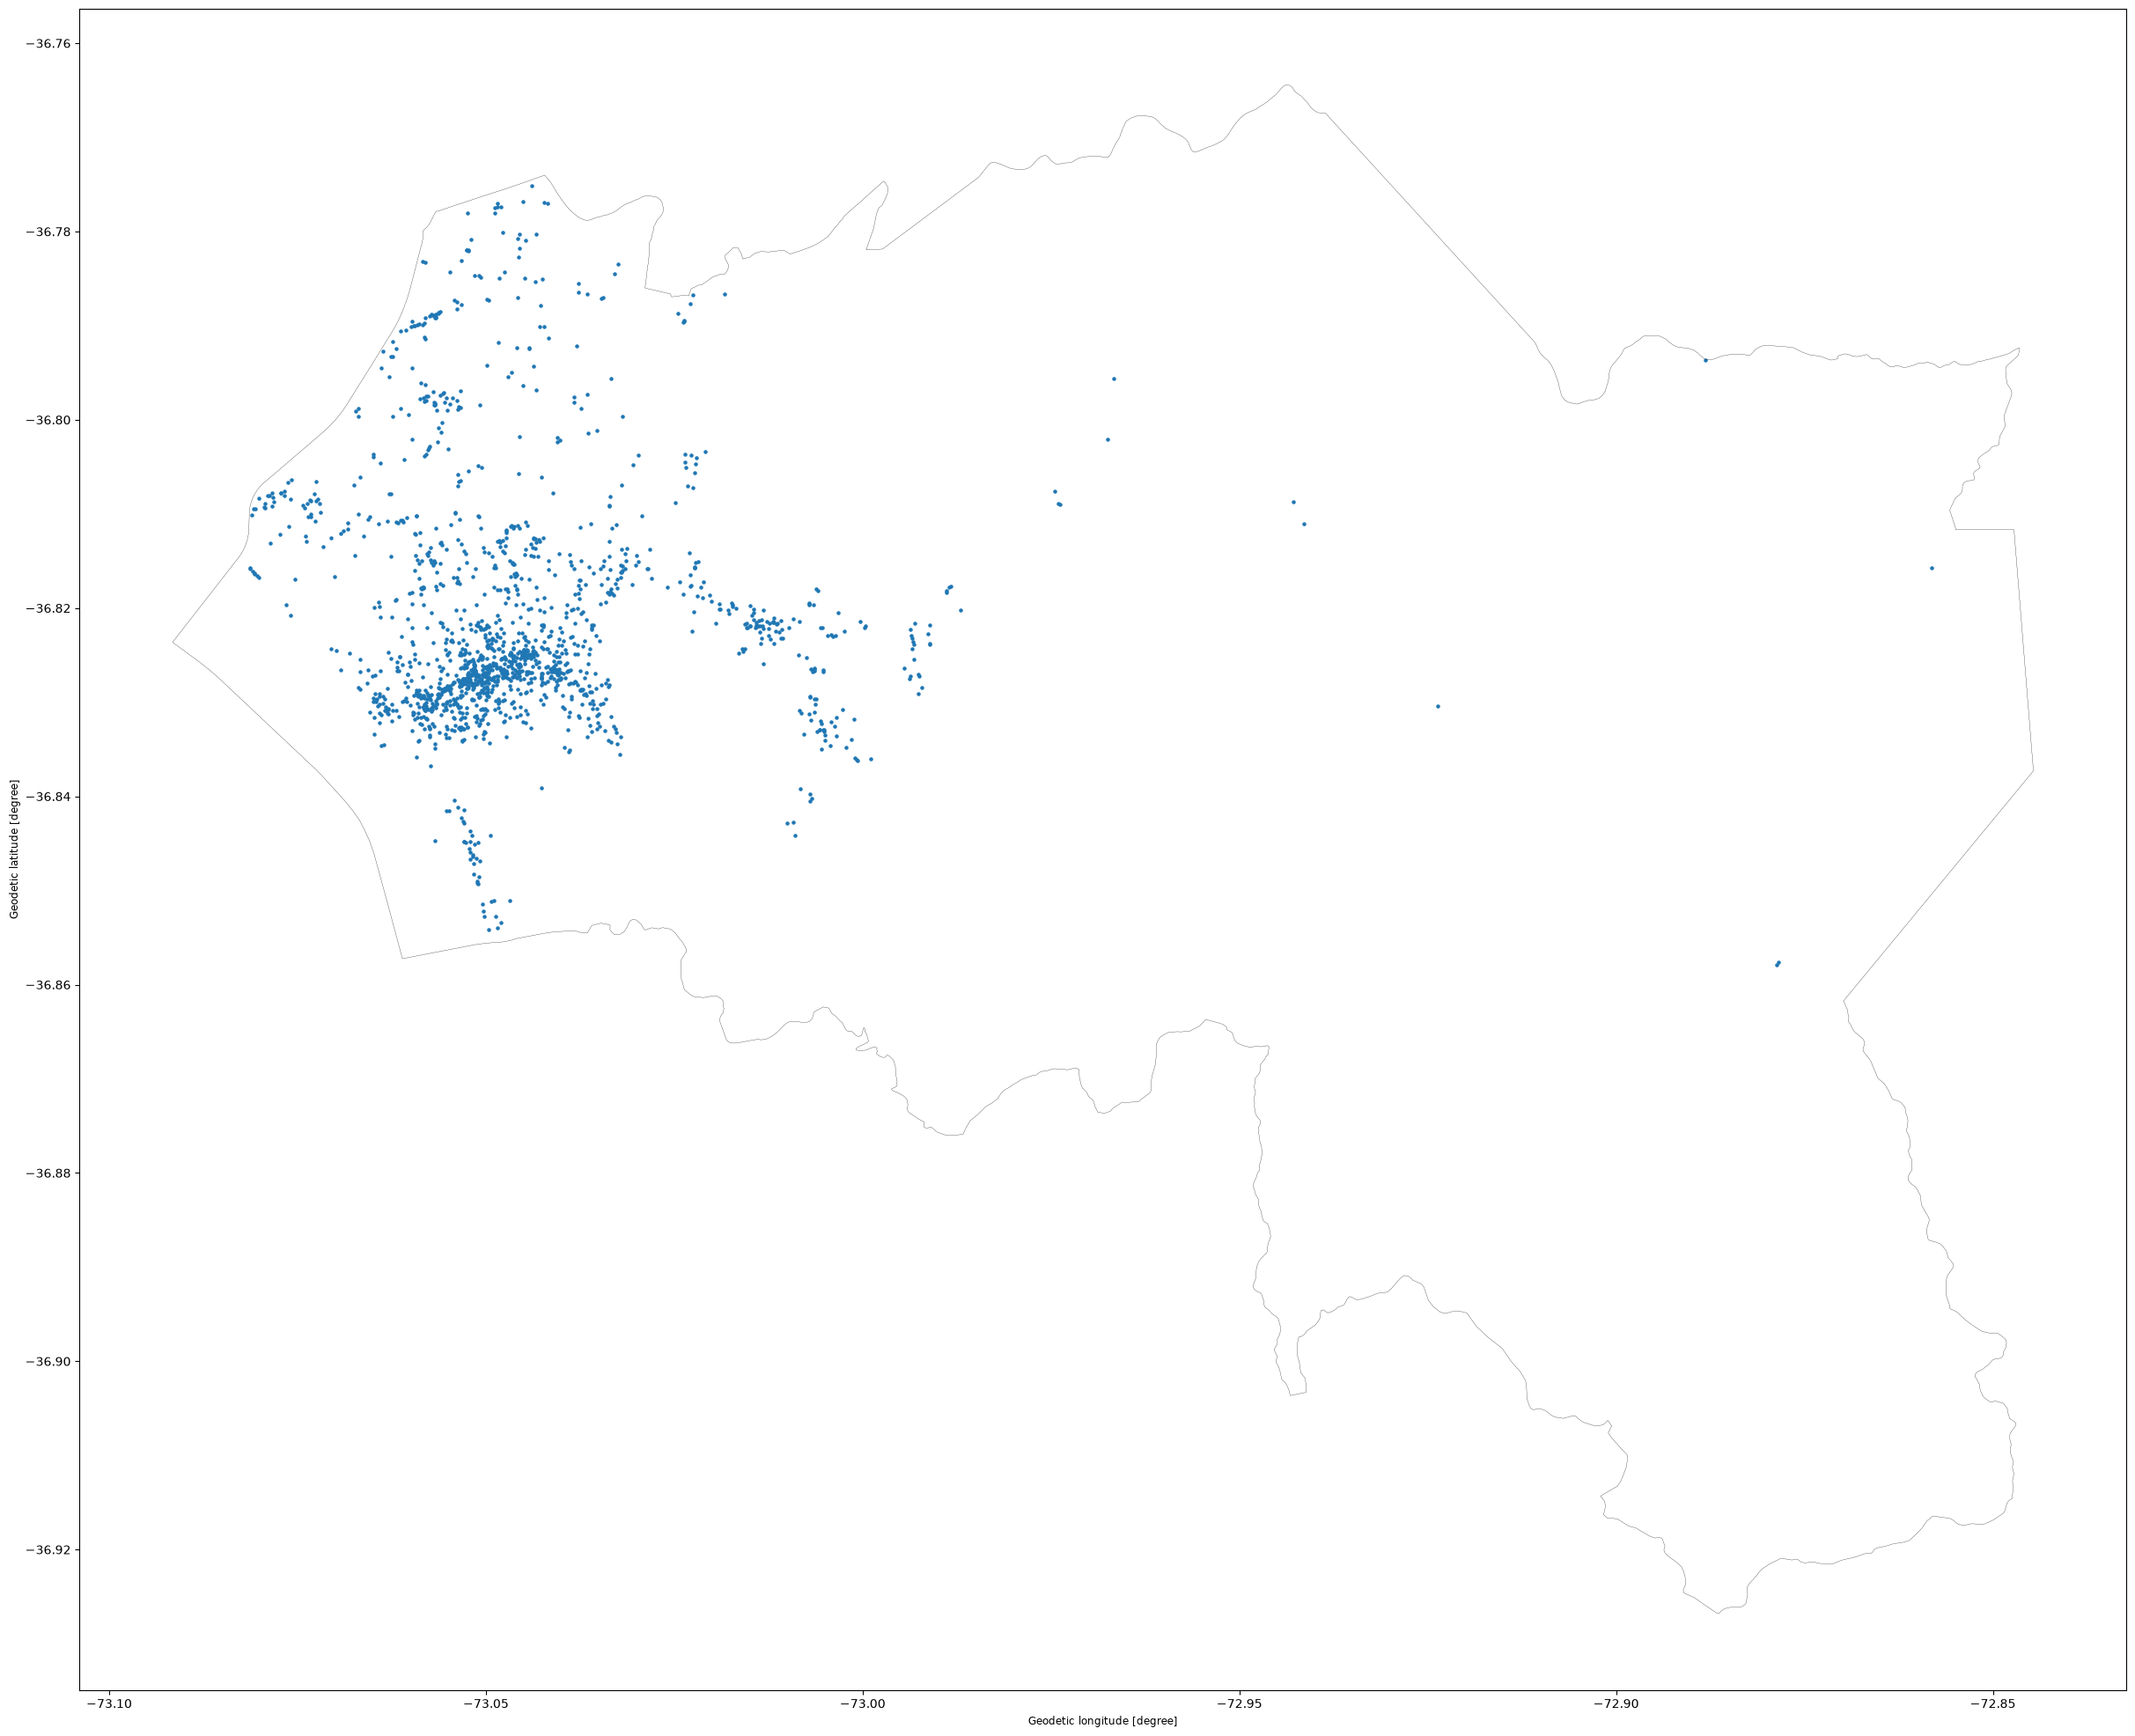

In [16]:
ax = pois.plot(figsize=(30,30), markersize=5)
# edges_gdf.plot(ax=ax, color="black", linewidth=0.1)
area_gdf.plot(ax=ax, color="none", linewidth=0.2)

---
polygon for waze partners

14


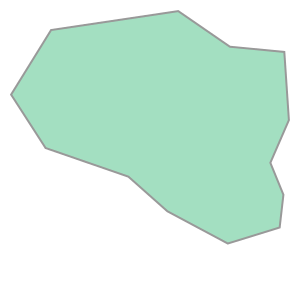

In [17]:
area = area_gdf.to_crs(32718).iloc[0].geometry
area = area.buffer(1000)
area = shapely.concave_hull(area, 0.2)
area = area.simplify(500)
print(len(area.exterior.coords))
area

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

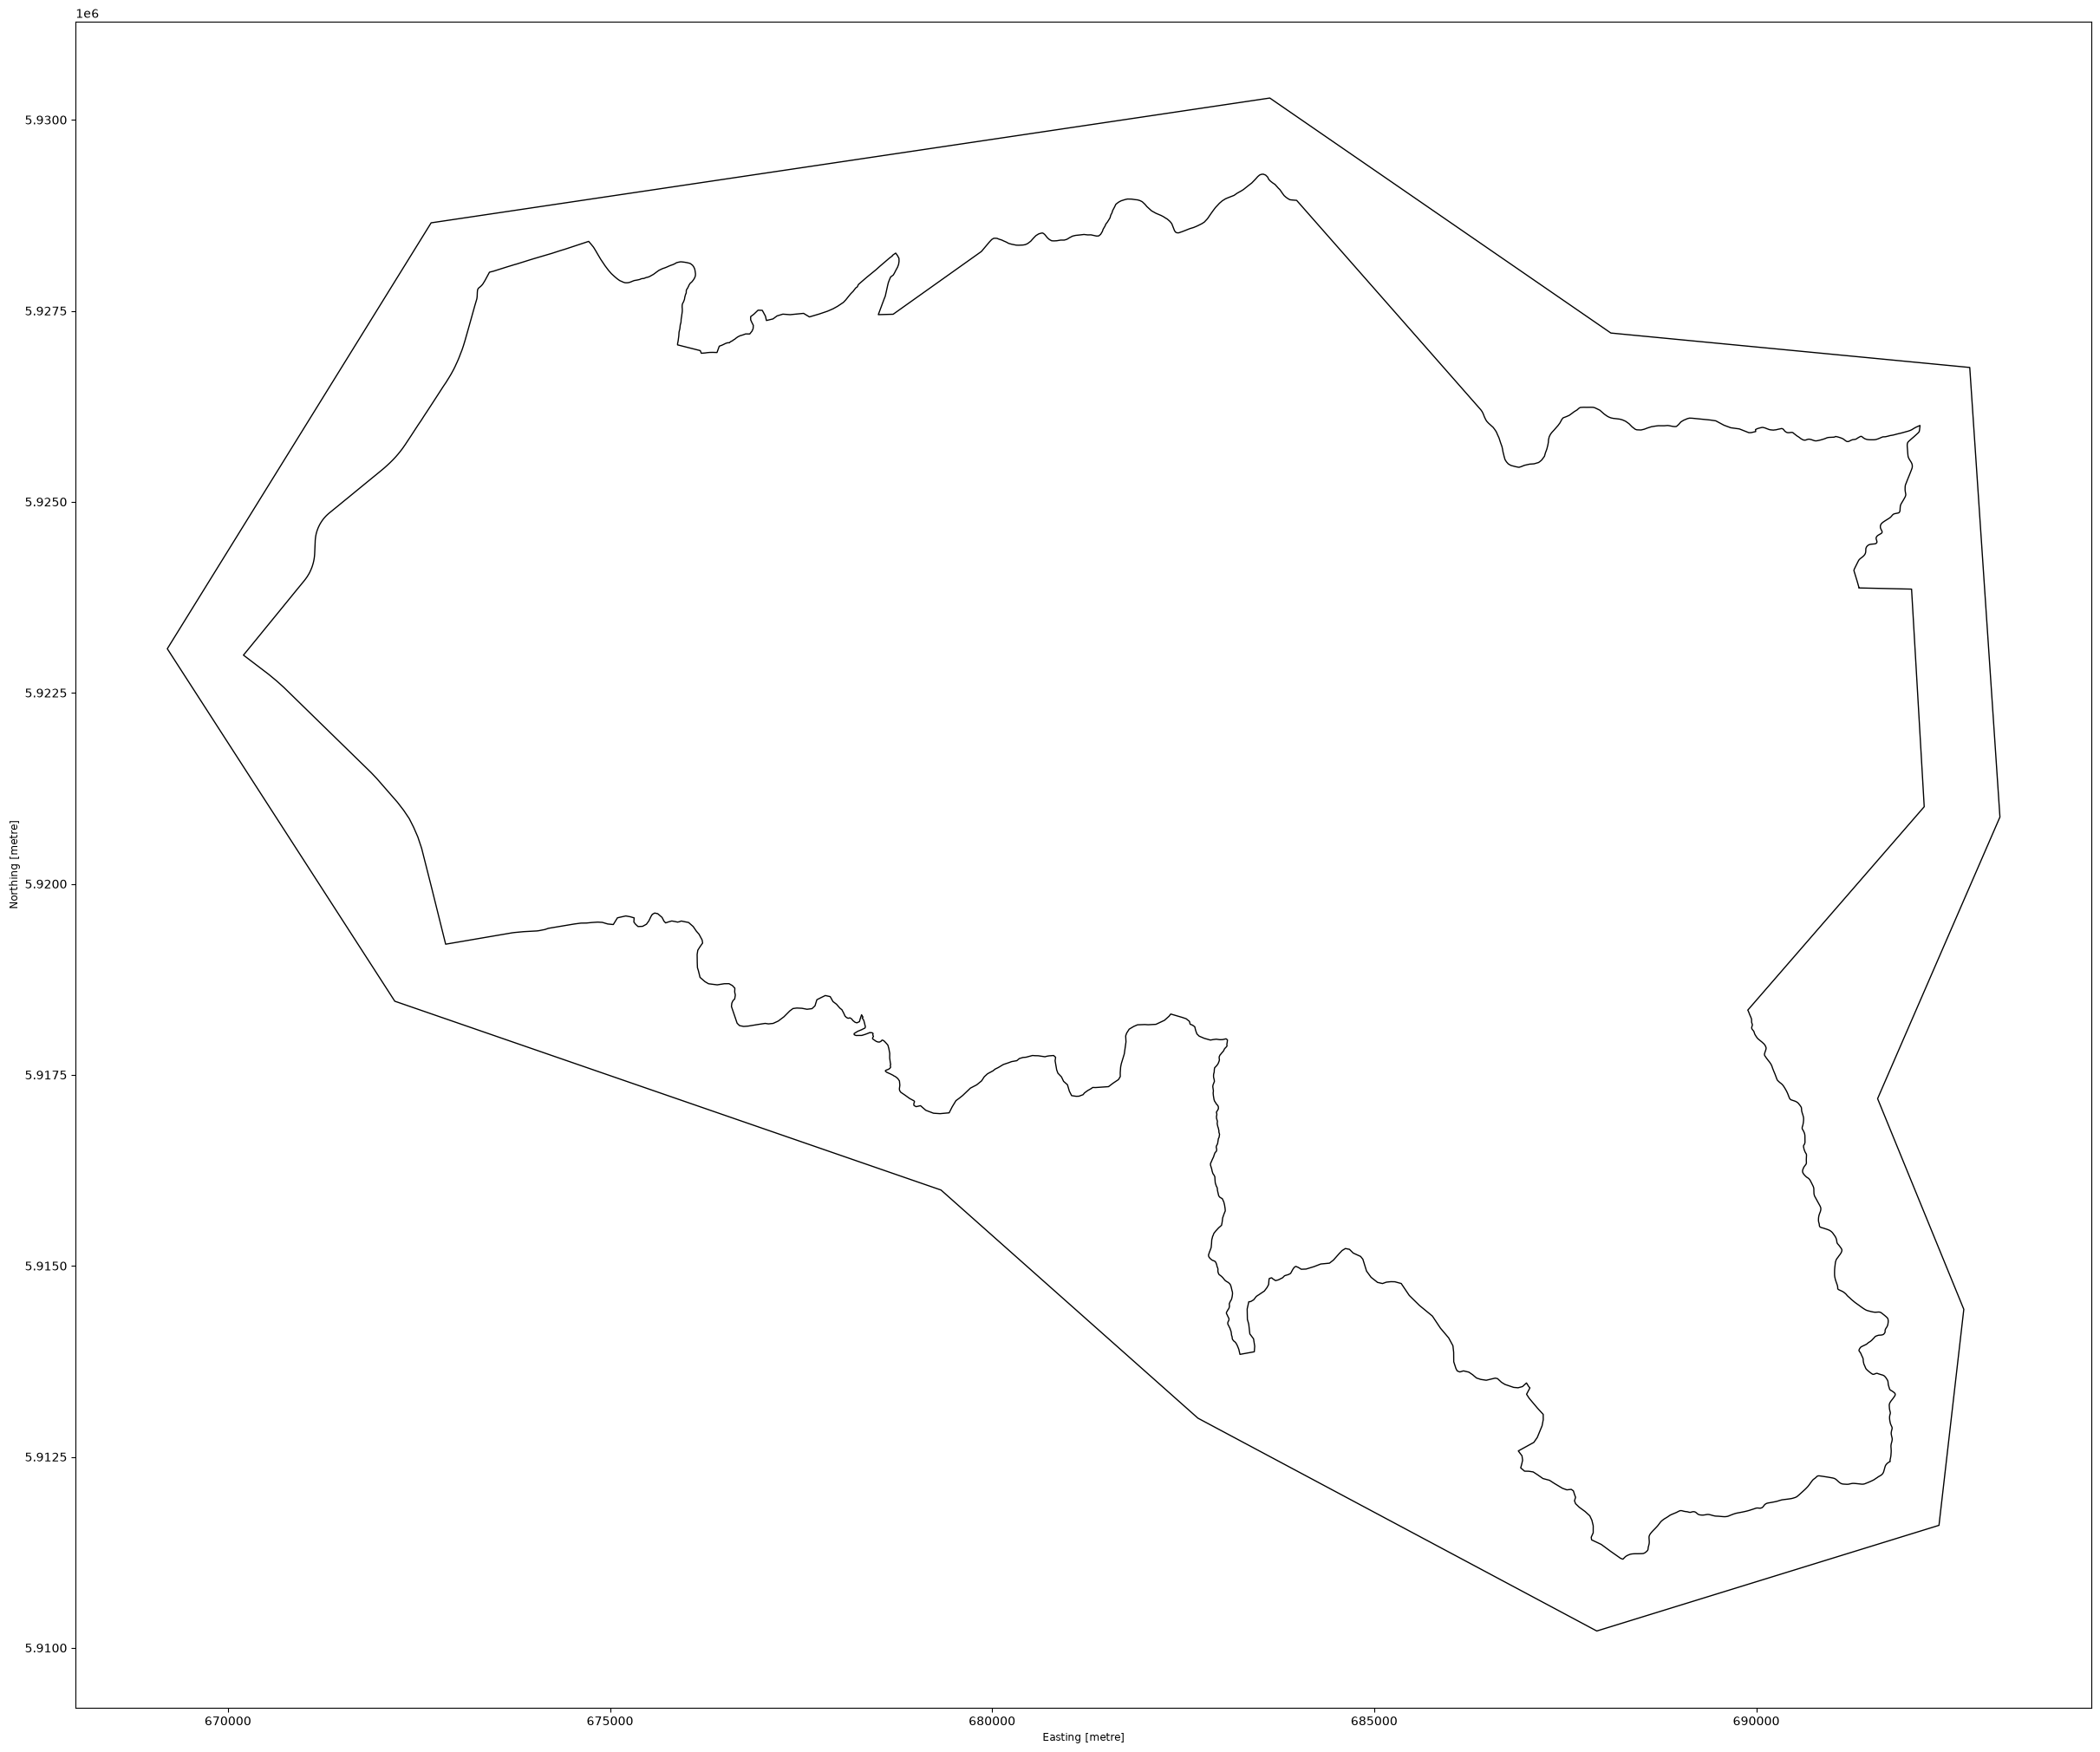

In [18]:
ax = gpd.GeoDataFrame(geometry=[area], crs=32718).plot(figsize=(30,30), color="none")
area_gdf.to_crs(32718).plot(ax=ax, color="none")

In [19]:
gpd.GeoDataFrame(geometry=[area], crs=32718).to_crs(4326).iloc[0].geometry.wkt

'POLYGON ((-73.06534770724241 -36.77221007702783, -72.94283553842045 -36.75543158586415, -72.89210754757364 -36.782265578792426, -72.83939731059624 -36.785381751056015, -72.83347912863859 -36.838305584391065, -72.85049202447173 -36.87183840950714, -72.83714184631572 -36.89644542066425, -72.84006664631713 -36.92198156907178, -72.8899665574953 -36.93534361199908, -72.94921174691352 -36.91127643923524, -72.98763358191215 -36.885021875519286, -73.06837018123112 -36.86408517491457, -73.1027755784348 -36.82306032450269, -73.06534770724241 -36.77221007702783))'

In [20]:
pois.to_parquet(f"data/{place_string}/pois.parquet")